# 🎓 Module 2: Understanding Embeddings

In this notebook, you'll learn:
1. What embeddings look like (they're just arrays of numbers!)
2. How to calculate similarity between texts
3. Why semantically similar texts have similar embeddings
4. How this enables semantic search in RAG

**Goal**: By the end, you'll understand exactly how your `embeddings.py` module works and why!

## Step 1: Import and Setup

Let's import your existing `EmbeddingModel` class.

In [3]:
# Add parent directory to path so we can import from src
import sys
sys.path.append('..')

from src.models.embeddings import EmbeddingModel
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

print("✅ Imports successful!")

INFO:matplotlib.font_manager:generated new fontManager


✅ Imports successful!


## Step 2: Create an Embedding Model

We'll use the default model: `all-MiniLM-L6-v2`

**What this model does**:
- Takes text as input
- Outputs a vector of 384 numbers
- Trained to put similar meanings close together in vector space

In [4]:
# Initialize the embedding model
embedder = EmbeddingModel()

print(f"Model loaded: {embedder.model_name}")
print(f"Embedding dimension: {embedder.get_embedding_dimension()}")
print("\nThis means each text is converted to 384 numbers!")

INFO:src.models.embeddings:Loading generic embedding model: sentence-transformers/all-MiniLM-L6-v2
INFO:sentence_transformers.SentenceTransformer:Use pytorch device_name: cpu
INFO:sentence_transformers.SentenceTransformer:Load pretrained SentenceTransformer: sentence-transformers/all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

INFO:src.models.embeddings:Embedding dimension: 384


Model loaded: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384

This means each text is converted to 384 numbers!


## Step 3: Your First Embedding

Let's convert a simple sentence to an embedding and see what it looks like.

In [5]:
# Convert text to embedding
text = "Machine learning is a subset of artificial intelligence."
embedding = embedder.encode(text)

print(f"Text: '{text}'")
print(f"\nEmbedding shape: {embedding.shape}")
print(f"\nFirst 10 numbers of the embedding:")
print(embedding[:10])
print("\n... and 374 more numbers!")

print("\n💡 Key insight: Text is now a mathematical vector!")

Text: 'Machine learning is a subset of artificial intelligence.'

Embedding shape: (1, 384)

First 10 numbers of the embedding:
[[-2.34592129e-02 -1.05811618e-02  7.19281882e-02  3.04254629e-02
   2.85594724e-02 -3.88255753e-02 -2.81977449e-02 -1.62505750e-02
  -5.76325357e-02 -3.36628314e-03 -5.13516329e-02  6.71795756e-03
   3.83127965e-02 -6.61401153e-02  1.21579394e-02  1.82332564e-02
  -3.89619581e-02 -2.27554031e-02 -6.06994331e-02 -4.28196676e-02
   3.27043235e-02  7.38159893e-03 -4.78378050e-02  1.16385194e-02
  -2.62261345e-03  2.76982486e-02  2.79765166e-02  5.66608086e-02
  -4.38165031e-02  6.88486472e-02  9.85199492e-03  1.58281031e-03
   4.30376176e-03  1.21635860e-02 -8.98835715e-03  4.14002687e-02
  -3.54325473e-02  5.99389374e-02  4.58479449e-02  7.83646572e-03
  -4.34180722e-02 -2.11208854e-02  1.24651883e-02 -9.54554509e-03
   5.26792184e-02  1.32122800e-01 -1.15970530e-01 -9.13518965e-02
  -5.94230965e-02 -9.37529188e-03 -1.29182786e-01 -3.88910770e-02
  -1.66933127e

## 🤔 Comprehension Check #1

**Question**: The embedding is just a list of 384 numbers. How do you think these numbers capture the "meaning" of the text?

**Hint**: Think about what the model was trained to do. It's not random numbers!

## Step 4: Similarity Between Embeddings

The magic happens when we compare embeddings!

We use **cosine similarity**: If two vectors point in similar directions, their meanings are similar.

In [6]:
# Let's create embeddings for related and unrelated texts
texts = [
    "Machine learning is a subset of artificial intelligence.",  # Original
    "Deep learning uses neural networks with multiple layers.",  # Related to AI/ML
    "AI and ML are transforming technology.",                    # Related (different words!)
    "The weather is nice today.",                               # Completely unrelated
    "I love eating pizza for dinner."                           # Completely unrelated
]

# Get embeddings for all texts
embeddings = embedder.encode(texts)

print(f"Created {len(embeddings)} embeddings")
print(f"Shape: {embeddings.shape}")
print("\nNow let's calculate similarities!")

Created 5 embeddings
Shape: (5, 384)

Now let's calculate similarities!


In [7]:
# Calculate similarity between first text and all others
reference = embeddings[0]  # "Machine learning..."

print("Reference text: 'Machine learning is a subset of artificial intelligence.'")
print("\nSimilarity scores (1.0 = identical, 0.0 = unrelated):\n")

for i, text in enumerate(texts):
    similarity = embedder.similarity(reference, embeddings[i])
    print(f"{similarity:.3f} - {text}")

Reference text: 'Machine learning is a subset of artificial intelligence.'

Similarity scores (1.0 = identical, 0.0 = unrelated):

1.000 - Machine learning is a subset of artificial intelligence.
0.489 - Deep learning uses neural networks with multiple layers.
0.546 - AI and ML are transforming technology.
-0.035 - The weather is nice today.
0.059 - I love eating pizza for dinner.


## 🤔 Comprehension Check #2

Look at the similarity scores above:

**Question 1**: Notice that "AI and ML are transforming technology" has high similarity even though it uses different words ("AI" vs "artificial intelligence", "ML" vs "machine learning"). Why does this happen?

**Question 2**: How would you explain this to someone who only knows keyword search?

**Think about this before moving to the next cell!**

## Step 5: Visualizing Embeddings

Embeddings are 384-dimensional, which we can't visualize. But we can use **PCA** (Principal Component Analysis) to compress them to 2D!

**Note**: This is a simplified view, but it helps you see the concept.

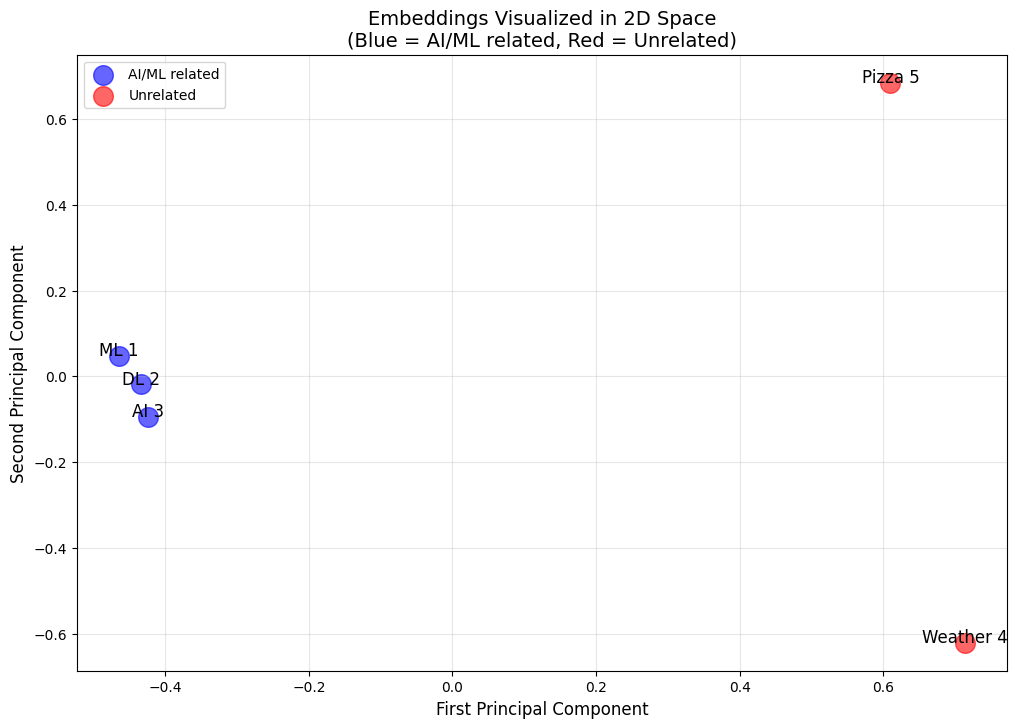


💡 Key insight: Similar topics cluster together in vector space!
This is how FAISS can find relevant chunks quickly.


In [8]:
# Reduce 384 dimensions to 2 dimensions for plotting
pca = PCA(n_components=2)
embeddings_2d = pca.fit_transform(embeddings)

# Create plot
plt.figure(figsize=(12, 8))
plt.scatter(embeddings_2d[:3, 0], embeddings_2d[:3, 1], c='blue', s=200, label='AI/ML related', alpha=0.6)
plt.scatter(embeddings_2d[3:, 0], embeddings_2d[3:, 1], c='red', s=200, label='Unrelated', alpha=0.6)

# Add labels
for i, txt in enumerate(['ML 1', 'DL 2', 'AI 3', 'Weather 4', 'Pizza 5']):
    plt.annotate(txt, (embeddings_2d[i, 0], embeddings_2d[i, 1]), fontsize=12, ha='center')

plt.xlabel('First Principal Component', fontsize=12)
plt.ylabel('Second Principal Component', fontsize=12)
plt.title('Embeddings Visualized in 2D Space\n(Blue = AI/ML related, Red = Unrelated)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("\n💡 Key insight: Similar topics cluster together in vector space!")
print("This is how FAISS can find relevant chunks quickly.")

## Step 6: How RAG Uses This

Now let's simulate what happens in RAG:

1. You have chunks from research papers (already embedded)
2. User asks a question (convert to embedding)
3. Find chunks with most similar embeddings
4. Return those chunks!

In [9]:
# Simulate document chunks from research papers
paper_chunks = [
    "RAG combines retrieval-based and generation-based approaches for question answering.",
    "The model first retrieves relevant documents using dense passage retrieval.",
    "Fine-tuning improves the model's performance on domain-specific tasks.",
    "FAISS enables efficient similarity search over large vector databases.",
    "Transformers use self-attention mechanisms to process sequential data.",
    "Climate change affects global temperature patterns and weather systems.",
    "Photosynthesis is the process by which plants convert sunlight into energy."
]

# Embed all chunks
chunk_embeddings = embedder.encode(paper_chunks)
print(f"✅ Embedded {len(paper_chunks)} paper chunks")

# Now simulate a user question
question = "How does retrieval work in RAG systems?"
question_embedding = embedder.encode(question)

print(f"\n❓ User question: '{question}'")
print("\n🔍 Finding most relevant chunks...\n")

# Calculate similarity with all chunks
similarities = []
for i, chunk_emb in enumerate(chunk_embeddings):
    sim = embedder.similarity(question_embedding, chunk_emb)
    similarities.append((sim, i, paper_chunks[i]))

# Sort by similarity (highest first)
similarities.sort(reverse=True)

# Show top 3 results
print("Top 3 most relevant chunks:\n")
for rank, (score, idx, text) in enumerate(similarities[:3], 1):
    print(f"Rank {rank} (Score: {score:.3f})")
    print(f"   {text}")
    print()

✅ Embedded 7 paper chunks

❓ User question: 'How does retrieval work in RAG systems?'

🔍 Finding most relevant chunks...

Top 3 most relevant chunks:

Rank 1 (Score: 0.408)
   RAG combines retrieval-based and generation-based approaches for question answering.

Rank 2 (Score: 0.267)
   The model first retrieves relevant documents using dense passage retrieval.

Rank 3 (Score: 0.219)
   Transformers use self-attention mechanisms to process sequential data.



## 🎯 What Just Happened?

You just simulated the **RETRIEVAL** step of RAG!

1. ✅ Converted question to embedding
2. ✅ Compared it with all chunk embeddings
3. ✅ Found the most similar chunks
4. ✅ These would be sent to the LLM as context!

Notice:
- Chunks about RAG, retrieval, and FAISS scored highest
- Chunks about climate and plants scored lowest
- **No keyword matching needed** - pure semantic similarity!

## 🧪 Your Turn: Experiment!

Now try these exercises to deepen your understanding:

### Exercise 1: Try Different Questions
Change the `question` variable above and see which chunks rank highest. Try:
- "What is FAISS used for?"
- "How do transformers work?"
- "Tell me about climate change"

### Exercise 2: Add Your Own Chunks
Add 3 more chunks to `paper_chunks` about a topic you know (e.g., your field of study). Then ask a question about it and see if the right chunks get retrieved!

### Exercise 3: Compare Embedding Models
Try a different embedding model:
```python
embedder_large = EmbeddingModel(model_name="sentence-transformers/all-mpnet-base-v2")
```
Compare the similarity scores. Are they different? Why might a larger model give different results?

**Write your experiments in the cells below!**

In [14]:
embedder_large = EmbeddingModel(model_name="sentence-transformers/all-mpnet-base-v2")

# Simulate document chunks from research papers
paper_chunks = [
    "RAG combines retrieval-based and generation-based approaches for question answering.",
    "The model first retrieves relevant documents using dense passage retrieval.",
    "Fine-tuning improves the model's performance on domain-specific tasks.",
    "FAISS enables efficient similarity search over large vector databases.",
    "Transformers use self-attention mechanisms to process sequential data.",
    "Climate change affects global temperature patterns and weather systems.",
    "Photosynthesis is the process by which plants convert sunlight into energy."
]

# Embed all chunks
chunk_embeddings = embedder.encode(paper_chunks)
print(f"✅ Embedded {len(paper_chunks)} paper chunks")

# Now simulate a user question
question = "Tell me about climate change."
question_embedding = embedder.encode(question)

print(f"\n❓ User question: '{question}'")
print("\n🔍 Finding most relevant chunks...\n")

# Calculate similarity with all chunks
similarities = []
for i, chunk_emb in enumerate(chunk_embeddings):
    sim = embedder.similarity(question_embedding, chunk_emb)
    similarities.append((sim, i, paper_chunks[i]))

# Sort by similarity (highest first)
similarities.sort(reverse=True)

# Show top 3 results
print("Top 3 most relevant chunks:\n")
for rank, (score, idx, text) in enumerate(similarities[:3], 1):
    print(f"Rank {rank} (Score: {score:.3f})")
    print(f"   {text}")
    print()

INFO:src.models.embeddings:Loading generic embedding model: sentence-transformers/all-mpnet-base-v2
INFO:sentence_transformers.SentenceTransformer:Use pytorch device_name: cpu
INFO:sentence_transformers.SentenceTransformer:Load pretrained SentenceTransformer: sentence-transformers/all-mpnet-base-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

INFO:src.models.embeddings:Embedding dimension: 768


✅ Embedded 7 paper chunks

❓ User question: 'Tell me about climate change.'

🔍 Finding most relevant chunks...

Top 3 most relevant chunks:

Rank 1 (Score: 0.658)
   Climate change affects global temperature patterns and weather systems.

Rank 2 (Score: 0.265)
   Photosynthesis is the process by which plants convert sunlight into energy.

Rank 3 (Score: 0.105)
   Transformers use self-attention mechanisms to process sequential data.



## 📚 Key Takeaways

By now you should understand:

1. ✅ **Embeddings are vectors** - just arrays of numbers (384 dimensions for MiniLM)
2. ✅ **Similar meanings = similar vectors** - this is learned during training
3. ✅ **Cosine similarity** measures how close two vectors are
4. ✅ **Semantic search** finds meaning, not just keywords
5. ✅ **RAG retrieval** is just similarity search with embeddings!

---

## 🤔 Final Comprehension Questions

Before moving to Module 3, answer these:

**Q1**: In your own words, explain what an embedding is and why it's useful for search.

**Q2**: Why does semantic search (embeddings) work better than keyword search for research papers?

**Q3**: Looking at your `src/models/embeddings.py` code - can you now explain what the `encode()` method does and why `normalize_embeddings=True` is useful?

---

**Next Module**: We'll learn how FAISS makes this search FAST even with millions of chunks!